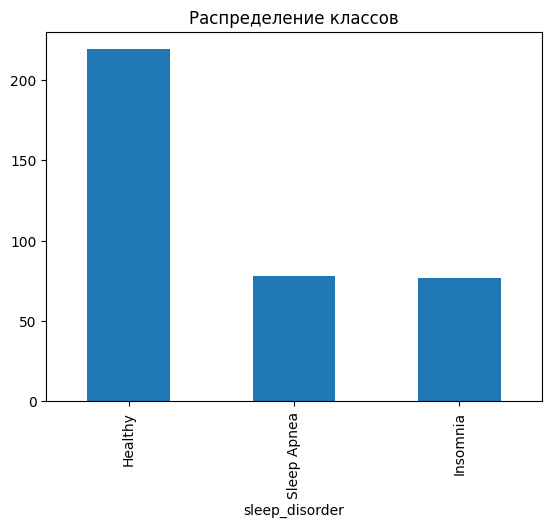

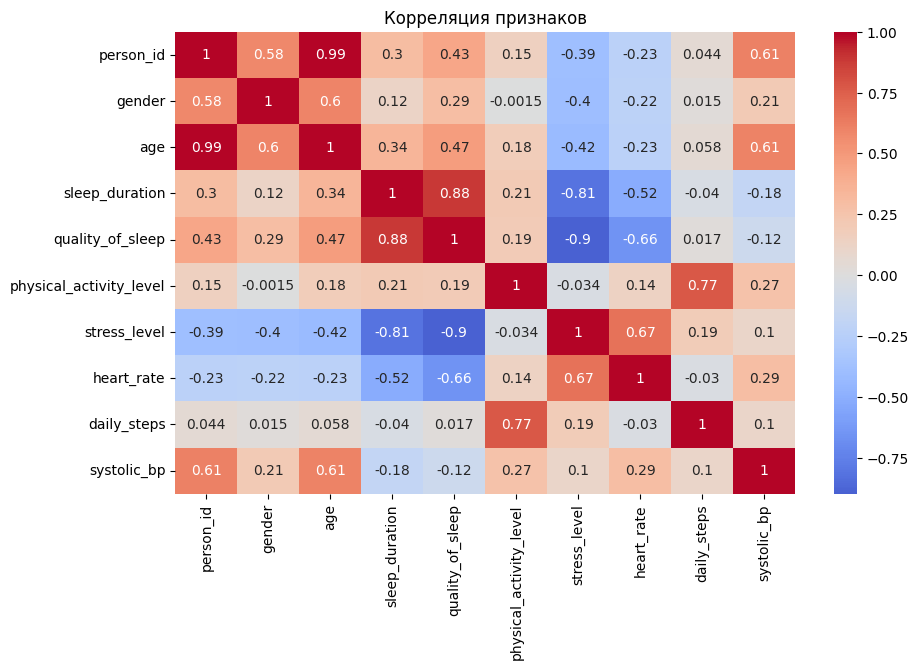

   gender  age  quality_of_sleep  physical_activity_level  heart_rate  \
0       0   27                 6                       42          77   
1       0   28                 6                       60          75   
2       0   28                 6                       60          75   
3       0   28                 4                       30          85   
4       0   28                 4                       30          85   

  sleep_disorder  systolic_bp  occupation_Accountant  occupation_Doctor  \
0        Healthy          126                      0                  0   
1        Healthy          125                      0                  1   
2        Healthy          125                      0                  1   
3    Sleep Apnea          140                      0                  0   
4    Sleep Apnea          140                      0                  0   

   occupation_Engineer  occupation_Lawyer  occupation_Manager  \
0                    0                  0    

In [3]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import MinMaxScaler
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import confusion_matrix, classification_report

df = pd.read_csv("sleep.csv")

df.columns = (
    df.columns.str.strip()
    .str.lower()
    .str.replace(" ", "_", regex=False)
    .str.replace("/", "_", regex=False)
)

target = "sleep_disorder"
df[target] = df[target].fillna("Healthy")
df["bmi_category"] = df["bmi_category"].replace({"Normal Weight": "Normal"})
df["occupation"] = df["occupation"].replace({"Sales Representative": "Salesperson"})
df["gender"] = df["gender"].map({"Male": 0, "Female": 1})
df["systolic_bp"] = df["blood_pressure"].str.split("/").str[0].astype(int)

df[target].value_counts().plot(kind="bar")
plt.title("Распределение классов")
plt.show()

plt.figure(figsize=(10, 6))
sns.heatmap(df.corr(numeric_only=True), annot=True, cmap="coolwarm", center=0)
plt.title("Корреляция признаков")
plt.show()

df = df.drop(columns=[
    "person_id",
    "blood_pressure",
    "sleep_duration",
    "daily_steps",
    "stress_level"
])

df = pd.get_dummies(df, columns=["occupation", "bmi_category"], dtype=int)

print(df.head())
print("Размер таблицы:", df.shape)

In [4]:
X = df.drop(columns=[target])
y = df[target]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3, random_state=42, stratify=y
)

scaler = MinMaxScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

models = {
    "KNN": KNeighborsClassifier(),
    "Logistic Regression": LogisticRegression(random_state=0),
    "Decision Tree": DecisionTreeClassifier(random_state=0)
}

for name, model in models.items():
    model.fit(X_train, y_train)
    y_pred = model.predict(X_test)

    print(f"\nМОДЕЛЬ {name}")
    print("Матрица ошибок:")
    print(confusion_matrix(y_test, y_pred))
    print("Отчёт:")
    print(classification_report(y_test, y_pred))


МОДЕЛЬ KNN
Матрица ошибок:
[[61  3  2]
 [ 1 19  3]
 [ 0  5 19]]
Отчёт:
              precision    recall  f1-score   support

     Healthy       0.98      0.92      0.95        66
    Insomnia       0.70      0.83      0.76        23
 Sleep Apnea       0.79      0.79      0.79        24

    accuracy                           0.88       113
   macro avg       0.83      0.85      0.83       113
weighted avg       0.89      0.88      0.88       113


МОДЕЛЬ Logistic Regression
Матрица ошибок:
[[61  2  3]
 [ 0 19  4]
 [ 0  3 21]]
Отчёт:
              precision    recall  f1-score   support

     Healthy       1.00      0.92      0.96        66
    Insomnia       0.79      0.83      0.81        23
 Sleep Apnea       0.75      0.88      0.81        24

    accuracy                           0.89       113
   macro avg       0.85      0.88      0.86       113
weighted avg       0.90      0.89      0.90       113


МОДЕЛЬ Decision Tree
Матрица ошибок:
[[64  1  1]
 [ 0 18  5]
 [ 0  3 21]]
Отч